# $\chi^2$ distribution

Lecture 2 (16/11) - Distributions

## Exercise

1. Generate $10^5$ sets of $n$ standard-normal random numbers $x$, and populate a histogram with

   $$\chi^2 = \sum_{i=1}^{n} x_i^2$$

2. Repeat point 1 for $n = 1,\ 2,\ 3,\ 5,\ 10,\ 20$.
3. Overlay the histograms with the theoretical $\chi^2$ distribution with the corresponding number of DOF, properly scaled to the number of generated values. **Do not use any predefined $\chi^2$ method.**

## Solution

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from math import gamma

import scipy.stats as stats
from scipy.stats import binom, poisson, chi2

### Functions

In [29]:
def chi2_pdf(x, k):
    with np.errstate(divide="ignore"):
        return x**(k/2 - 1) * np.exp(-x/2) / (2**(k/2) * gamma(k/2))

### Plots

In [30]:
n_rep = 10**5
ns = [1, 2, 3, 5, 10, 20]
rng = np.random.default_rng(12345)

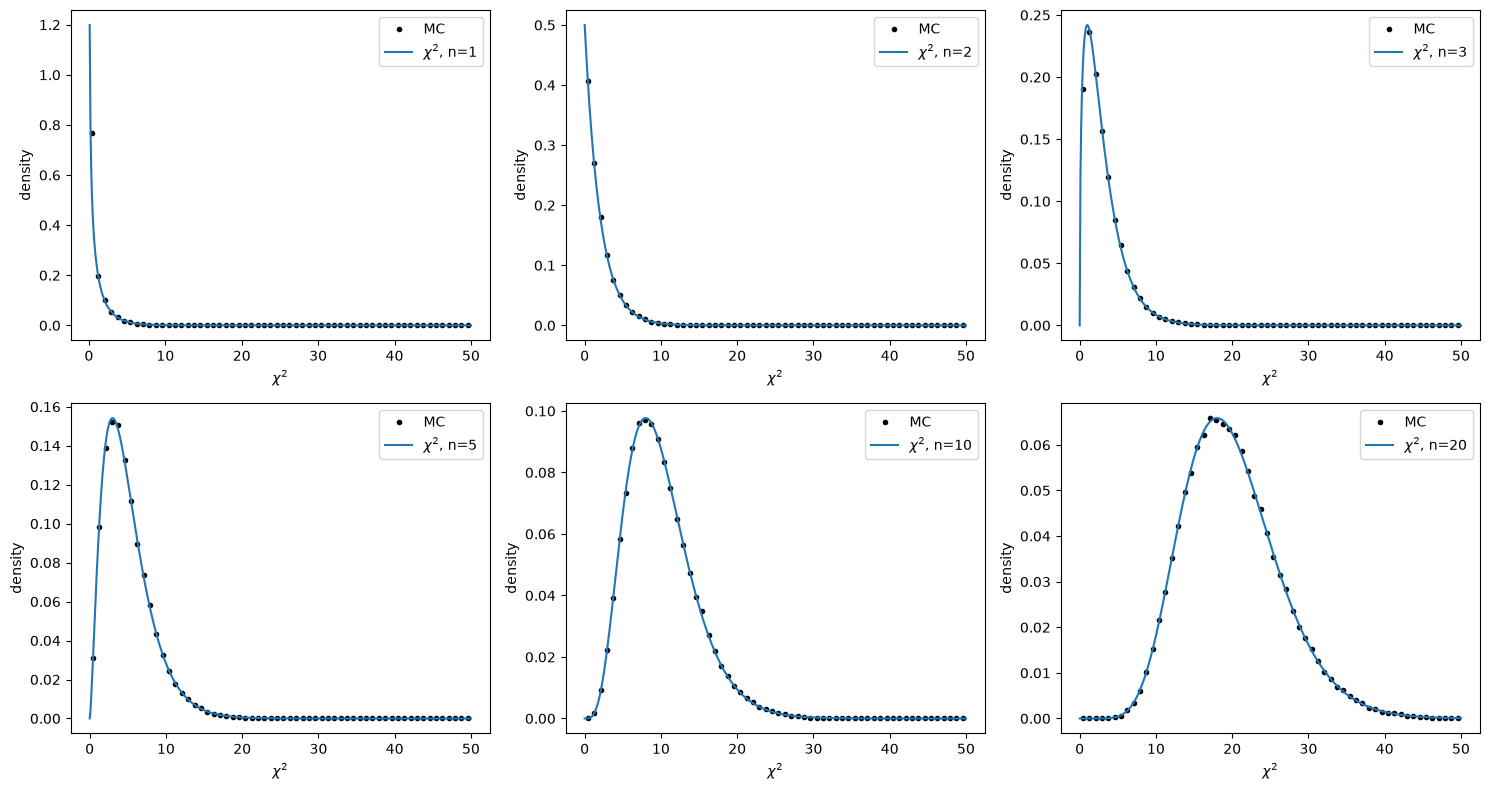

In [39]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, n in zip(axes.flat, ns):
    y = rng.standard_normal((n_rep, n))     # n_rep sets of n standard normals
    x2 = np.sum(y**2, axis=1)               # chi2 = sum of y_i^2

    bins = np.linspace(0, 50, 61)
    counts, _ = np.histogram(x2, bins=bins, density=True)
    xc = 0.5 * (bins[1:] + bins[:-1])

    xx = np.linspace(0, bins[-1], 500)
    ax.plot(xc, counts, "o", ms=3, c="k", label="MC")
    ax.plot(xx, chi2_pdf(xx, n), label=fr"$\chi^2$, n={n}")
    ax.set_xlabel(r"$\chi^2$"); ax.set_ylabel("density")
    ax.legend()

fig.tight_layout()
plt.show()

## Conclusions

- **Agreement with theory.** For all $n$ the simulated histograms follow the
  $\chi^2$ distribution.
- **Shape.** For $n=1$ the distribution diverges at zero, for $n=2$ it is an
  exponential (as in the previous exercise, since $y_1^2+y_2^2$ is the squared
  radius of a 2D Gaussian). For $n\geq3$ it has a peak at $n-2$ and a right tail.
- **Large $n$.** The distribution becomes more symmetric as $n$ grows, and at
  $n=20$ it is close to a Gaussian $N(n,2n)$, as expected from the central
  limit theorem.
